# LeetCode #329: Longest Increasing Path in a Matrix

https://leetcode.com/problems/longest-increasing-path-in-a-matrix/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| DFS with Memoization ★ | O(m×n) | O(m×n) |
| Topological Sort (BFS) | O(m×n) | O(m×n) |
| DFS without Memoization | O(2^(m×n)) | O(m×n) |

## Understanding the Methods
### DFS with Memoization (Optimal)
For each cell, compute the longest increasing path starting from it via DFS, caching results. Since values must strictly increase, there are no cycles, so memoization ensures each cell is computed exactly once. The answer is the maximum over all cells.

### Topological Sort (BFS)
Model the matrix as a DAG where edges go from smaller to larger neighbors. Use topological sort (peel cells with in-degree 0). The number of peeling rounds is the longest path length.

### DFS without Memoization
Naive DFS exploring all paths. Exponential time due to recomputation of overlapping subproblems.

## Solutions

### C#

In [ ]:
public class Solution {
    private int[][] dirs = { new[]{0,1}, new[]{0,-1}, new[]{1,0}, new[]{-1,0} };

    public int LongestIncreasingPath(int[][] matrix) {
        int m = matrix.Length, n = matrix[0].Length;
        var memo = new int[m, n];
        int ans = 0;
        for (int i = 0; i < m; i++)
            for (int j = 0; j < n; j++)
                ans = Math.Max(ans, Dfs(matrix, memo, i, j, m, n));
        return ans;
    }

    private int Dfs(int[][] matrix, int[,] memo, int i, int j, int m, int n) {
        if (memo[i, j] != 0) return memo[i, j];
        int best = 1;
        foreach (var d in dirs) {
            int ni = i + d[0], nj = j + d[1];
            if (ni >= 0 && ni < m && nj >= 0 && nj < n && matrix[ni][nj] > matrix[i][j])
                best = Math.Max(best, 1 + Dfs(matrix, memo, ni, nj, m, n));
        }
        memo[i, j] = best;
        return best;
    }
}

### Python

In [ ]:
from functools import cache

class Solution:
    def longestIncreasingPath(self, matrix: list[list[int]]) -> int:
        m, n = len(matrix), len(matrix[0])

        @cache
        def dfs(i: int, j: int) -> int:
            best = 1
            for di, dj in ((0,1),(0,-1),(1,0),(-1,0)):
                ni, nj = i + di, j + dj
                if 0 <= ni < m and 0 <= nj < n and matrix[ni][nj] > matrix[i][j]:
                    best = max(best, 1 + dfs(ni, nj))
            return best

        return max(dfs(i, j) for i in range(m) for j in range(n))

### Go

In [ ]:
func longestIncreasingPath(matrix [][]int) int {
    m, n := len(matrix), len(matrix[0])
    memo := make([][]int, m)
    for i := range memo {
        memo[i] = make([]int, n)
    }
    dirs := [][2]int{{0,1},{0,-1},{1,0},{-1,0}}

    var dfs func(i, j int) int
    dfs = func(i, j int) int {
        if memo[i][j] != 0 {
            return memo[i][j]
        }
        best := 1
        for _, d := range dirs {
            ni, nj := i+d[0], j+d[1]
            if ni >= 0 && ni < m && nj >= 0 && nj < n && matrix[ni][nj] > matrix[i][j] {
                if v := 1 + dfs(ni, nj); v > best {
                    best = v
                }
            }
        }
        memo[i][j] = best
        return best
    }

    ans := 0
    for i := 0; i < m; i++ {
        for j := 0; j < n; j++ {
            if v := dfs(i, j); v > ans {
                ans = v
            }
        }
    }
    return ans
}

### Rust

In [ ]:
impl Solution {
    pub fn longest_increasing_path(matrix: Vec<Vec<i32>>) -> i32 {
        let m = matrix.len();
        let n = matrix[0].len();
        let mut memo = vec![vec![0i32; n]; m];
        let mut ans = 0;
        for i in 0..m {
            for j in 0..n {
                ans = ans.max(Self::dfs(&matrix, &mut memo, i, j, m, n));
            }
        }
        ans
    }

    fn dfs(matrix: &Vec<Vec<i32>>, memo: &mut Vec<Vec<i32>>, i: usize, j: usize, m: usize, n: usize) -> i32 {
        if memo[i][j] != 0 { return memo[i][j]; }
        let mut best = 1;
        for (di, dj) in [(0i32,1i32),(0,-1),(1,0),(-1,0)] {
            let ni = i as i32 + di;
            let nj = j as i32 + dj;
            if ni >= 0 && ni < m as i32 && nj >= 0 && nj < n as i32 {
                let (ni, nj) = (ni as usize, nj as usize);
                if matrix[ni][nj] > matrix[i][j] {
                    best = best.max(1 + Self::dfs(matrix, memo, ni, nj, m, n));
                }
            }
        }
        memo[i][j] = best;
        best
    }
}

## Example Scenarios

From each cell, DFS to strictly-larger 4-directional neighbors; `@cache` memoizes each cell's longest path so the whole grid is solved in $O(m \cdot n)$. The answer is the max over all starting cells. Because moves must strictly increase, the implicit graph is a DAG — no cycles, so memoization is safe.

### 1. Common Case

**Input:** `matrix = [[9,9,4],[6,6,8],[2,1,1]]`

Longest strictly increasing path: `1 → 2 → 6 → 9` at cells (2,1)→(2,0)→(1,0)→(0,0). **Output:** `4`.

### 2. Slightly Complex — snake path

**Input:** `matrix = [[1,2],[4,3]]`

The path wraps around the grid: `1 → 2 → 3 → 4` at (0,0)→(0,1)→(1,1)→(1,0). Direction changes twice, yet memoized DFS still finds length **4**.

### 3. Edge Case: Time Factor — single increasing row

**Input:** `matrix = [[1,2,3,4]]`

One fully increasing line. Without memoization, overlapping suffixes would re-expand; `@cache` makes every cell computed once → $O(m \cdot n)$. **Output:** `4`.

### 4. Edge Case: Space Factor — all equal values

**Input:** `matrix = [[3,3],[3,3]]`

No neighbor is strictly greater, so every DFS returns 1 immediately. The memo table still occupies $O(m \cdot n)$ space (plus recursion stack bounded by the longest path). **Output:** `1`.

### 5. Almost-Impossible but Plausible — single cell

**Input:** `matrix = [[5]]`

A lone cell has no neighbors; `best = 1` with no recursion. **Output:** `1`. The base case needs no special handling — the direction loop simply finds nothing in range.

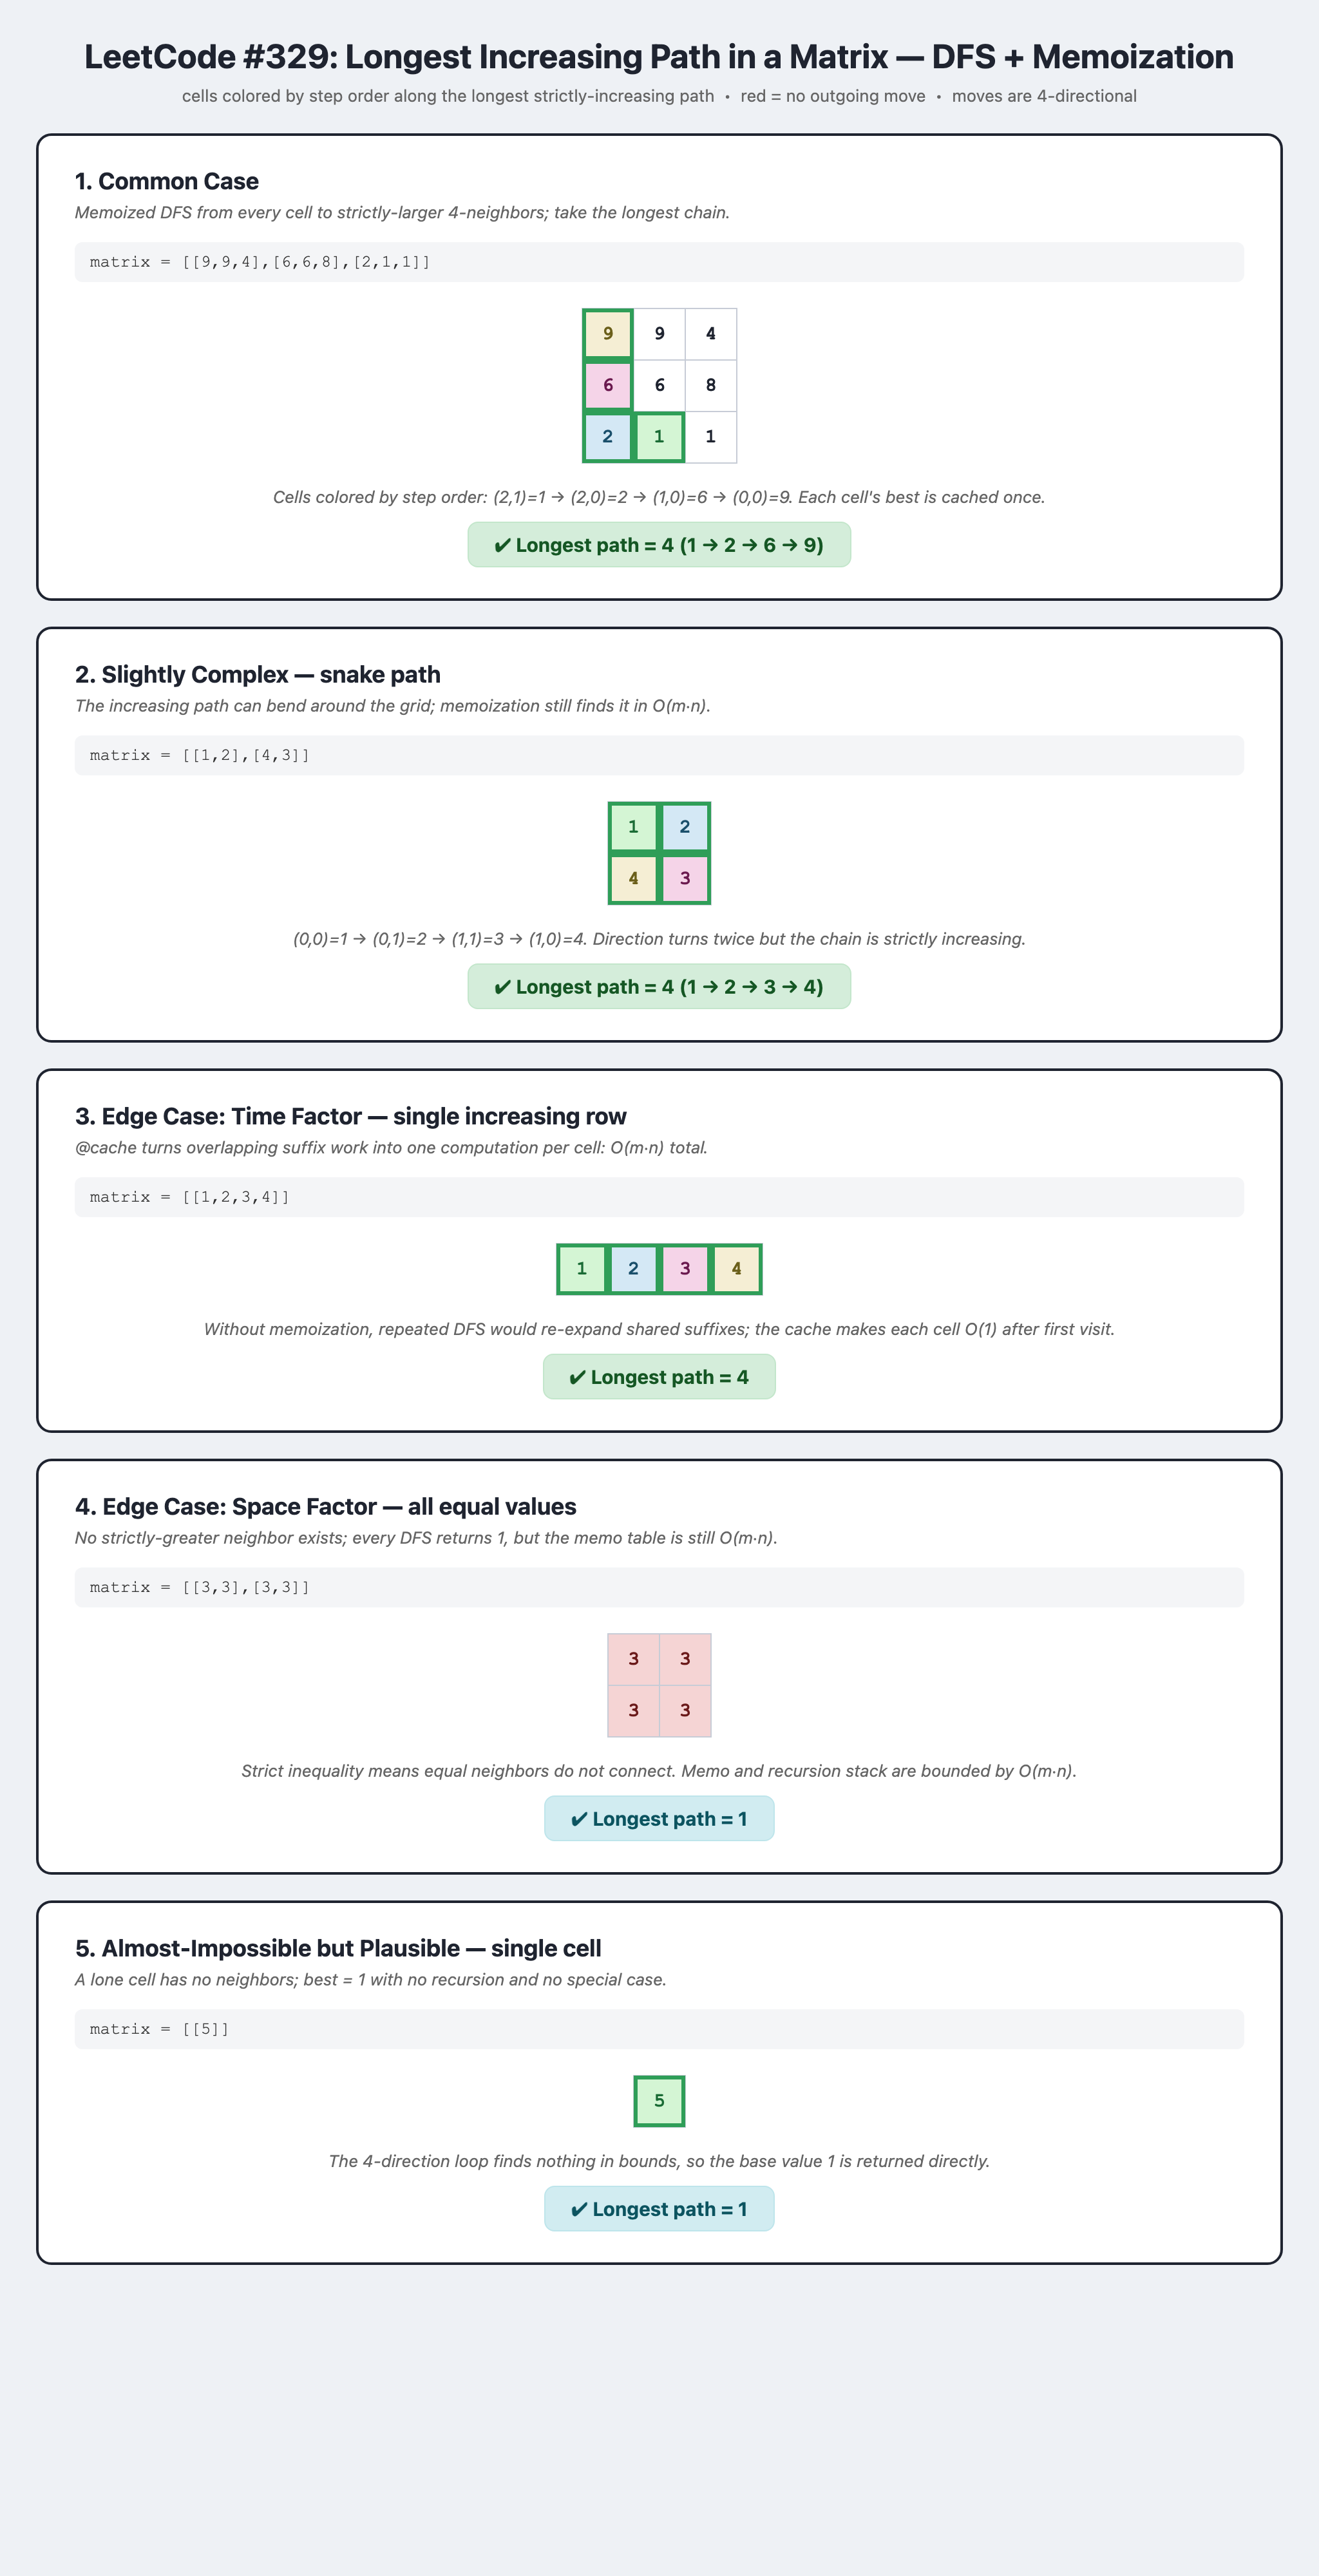